# 07. KNN Product Recommendation System — Collaborative Filtering

**Project:** E-Commerce Customer Analytics  
**Objective:** Build and evaluate a real-data collaborative filtering recommender using **K-Nearest Neighbors (`Cosine` similarity over sparse customer–product purchases)**, and save the fitted system (`models/knn_recommender.joblib`) for interactive Streamlit deployment.

> **Interaction & Modeling Rules:**
> - Uses **only** real `customer_id`, `stock_code`, `quantity`, and transaction records (`sales` with `has_customer_id == True`, `is_cancelled == False`, `is_merchandise == True`, excluding non-product shipping/fee codes `POST`, `DOT`, `C2`, `D`, `M`).
> - Repeated purchases of an item by the same customer are summed and dampened with `log1p(total_quantity)` so wholesale bulk orders do not overpower similarity calculations.
> - Zero fabricated ratings, reviews, or user demographics are introduced.

Identified merchandise purchase rows: 776,596
Unique (customer, product) pairs: 480,988
Interaction matrix shape: 5,852 customers x 4,621 products
Matrix sparsity: 98.22% empty
Customer distinct SKUs bought -> median: 45, 1-item cold-history customers: 121
Product buyer reach -> median: 53, max: 1,490


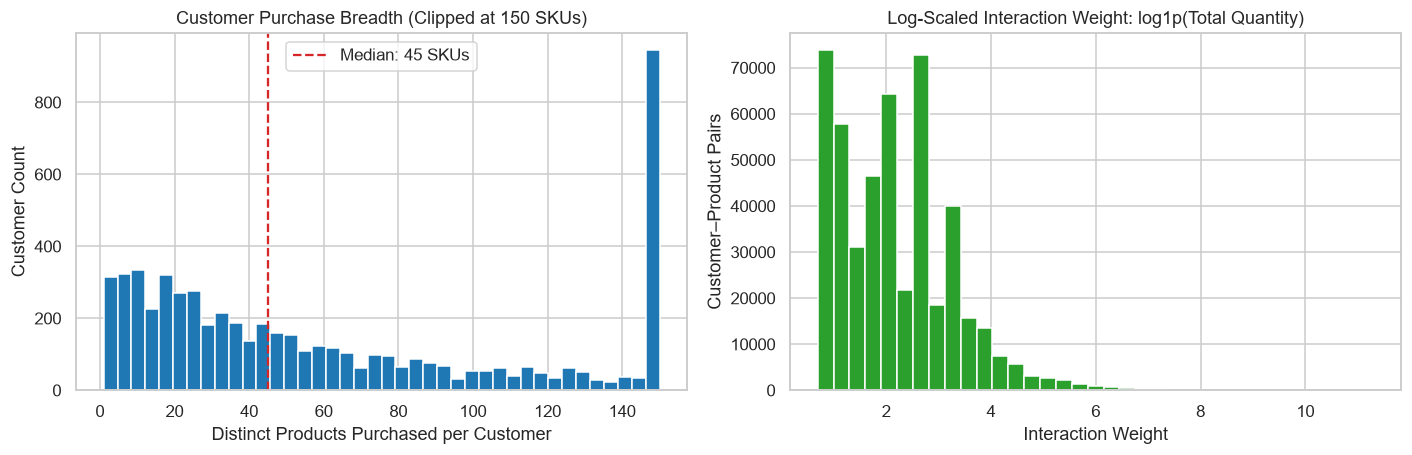

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.recommender import (
    ItemKNNRecommender,
    UserKNNRecommender,
    build_interaction_table,
    build_sparse_matrix,
    evaluate_recommender_holdout,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

TX_PATH = PROJECT_ROOT / "dataset" / "processed" / "analytics" / "transaction_features.csv"
VIZ_DIR = PROJECT_ROOT / "visualizations"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
for d in (VIZ_DIR, MODELS_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

tx_df = pd.read_csv(
    TX_PATH,
    dtype={"invoice": "string", "stock_code": "string", "customer_id": "Int64", "description": "string"},
    parse_dates=["invoice_date"],
)

sales_merch = tx_df[tx_df["has_customer_id"] & (~tx_df["is_cancelled"]) & tx_df["is_merchandise"]].copy()
full_inter = build_interaction_table(sales_merch)
R_full, cust_ids, item_ids, _, _ = build_sparse_matrix(full_inter)

sparsity_pct = (1.0 - R_full.nnz / (R_full.shape[0] * R_full.shape[1])) * 100
cust_basket_depth = full_inter.groupby("customer_id")["stock_code"].count()
item_reach = full_inter.groupby("stock_code")["customer_id"].count()

print(f"Identified merchandise purchase rows: {len(sales_merch):,}")
print(f"Unique (customer, product) pairs: {len(full_inter):,}")
print(f"Interaction matrix shape: {R_full.shape[0]:,} customers x {R_full.shape[1]:,} products")
print(f"Matrix sparsity: {sparsity_pct:.2f}% empty")
print(f"Customer distinct SKUs bought -> median: {cust_basket_depth.median():.0f}, 1-item cold-history customers: {int((cust_basket_depth == 1).sum()):,}")
print(f"Product buyer reach -> median: {item_reach.median():.0f}, max: {item_reach.max():,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].hist(cust_basket_depth.clip(upper=150), bins=40, color="#1f77b4", edgecolor="white")
axes[0].axvline(cust_basket_depth.median(), color="#d62728", linestyle="--", label=f"Median: {cust_basket_depth.median():.0f} SKUs")
axes[0].set_title("Customer Purchase Breadth (Clipped at 150 SKUs)")
axes[0].set_xlabel("Distinct Products Purchased per Customer")
axes[0].set_ylabel("Customer Count")
axes[0].legend()

axes[1].hist(full_inter["interaction_weight"], bins=35, color="#2ca02c", edgecolor="white")
axes[1].set_title("Log-Scaled Interaction Weight: log1p(Total Quantity)")
axes[1].set_xlabel("Interaction Weight")
axes[1].set_ylabel("Customer–Product Pairs")

plt.tight_layout()
fig.savefig(VIZ_DIR / "07_knn_matrix_sparsity.png", dpi=150, bbox_inches="tight")
plt.show()

### Interaction Matrix & Sparsity Analysis
- Aggregating **776,596** identified merchandise sales rows produces a sparse **`5,852 × 4,621`** customer–product matrix with **`480,988` non-zero entries** (**`98.22%` sparsity**).
- To suppress spurious `cosine = 1.0` similarity ties from ultra-rare 1-to-4-buyer items, the Item-KNN model filters the collaborative filtering graph to items with **`min_item_customers >= 5`**, while preserving cold-start popularity fallbacks for sparse/unseen customers.
- Using `scipy.sparse.csr_matrix` stores only observed non-zero entries in memory while enabling fast **Cosine similarity** (`1 - cosine_distance`) across thousands of products.
- Applying `log1p(total_quantity)` compresses extreme bulk quantities smoothly into a compact range (`~0.69` for 1 unit up to `~11.8` for bulk orders), ensuring repeated buyers contribute strong signal without single wholesale packs dominating cosine angles.

,model_name,k,exclude_seen,n_eval_customers,precision_at_k,recall_at_k,hit_rate_at_k,coverage_pct,unique_items_recommended
0,Popularity Baseline,5,True,2196,0.0476,0.0106,0.1990,1.03,46
1,Popularity Baseline,10,True,2196,0.0412,0.0168,0.2910,1.80,80
2,User-Based KNN (Cosine),5,True,2196,0.0703,0.0188,0.2609,17.14,762
3,User-Based KNN (Cosine),10,True,2196,0.0593,0.0304,0.3597,23.28,1035
4,Item-Based KNN (Cosine),5,True,2196,0.0721,0.0197,0.2600,17.46,776
5,Item-Based KNN (Cosine),10,True,2196,0.0668,0.0355,0.3848,24.72,1099
6,Item-Based KNN (Incl. Repeats),5,False,2272,0.2123,0.0369,0.5163,18.97,843
7,Item-Based KNN (Incl. Repeats),10,False,2272,0.1952,0.0681,0.6461,26.68,1186


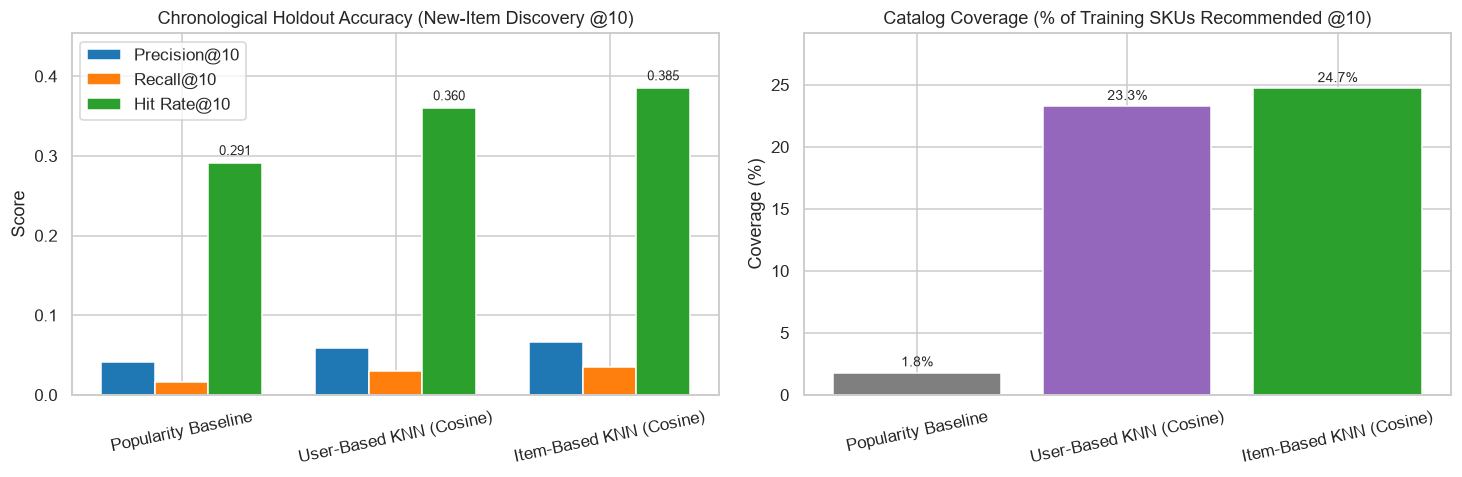

In [2]:
CUTOFF_DATE = pd.Timestamp("2011-09-11")
train_sales = sales_merch[sales_merch["invoice_date"] < CUTOFF_DATE].copy()
holdout_sales = sales_merch[sales_merch["invoice_date"] >= CUTOFF_DATE].copy()

item_knn_eval_model = ItemKNNRecommender(n_neighbors=25, min_history_for_cf=1, min_item_customers=5).fit(train_sales)
user_knn_eval_model = UserKNNRecommender(n_neighbors=25).fit(train_sales)
pop_rank = item_knn_eval_model.popular_items_

eval_frames = [
    evaluate_recommender_holdout(train_sales, holdout_sales, None, "Popularity Baseline", pop_rank, k_values=(5, 10), exclude_seen=True),
    evaluate_recommender_holdout(train_sales, holdout_sales, user_knn_eval_model, "User-Based KNN (Cosine)", pop_rank, k_values=(5, 10), exclude_seen=True),
    evaluate_recommender_holdout(train_sales, holdout_sales, item_knn_eval_model, "Item-Based KNN (Cosine)", pop_rank, k_values=(5, 10), exclude_seen=True),
    evaluate_recommender_holdout(train_sales, holdout_sales, item_knn_eval_model, "Item-Based KNN (Incl. Repeats)", pop_rank, k_values=(5, 10), exclude_seen=False),
]
eval_results_df = pd.concat(eval_frames, ignore_index=True)
display(eval_results_df)

# Chart: Compare @10 New-Item Discovery Metrics across models
new10 = eval_results_df[(eval_results_df["k"] == 10) & (eval_results_df["exclude_seen"] == True)].copy()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

x = np.arange(len(new10))
w = 0.25
axes[0].bar(x - w, new10["precision_at_k"], width=w, color="#1f77b4", label="Precision@10")
axes[0].bar(x, new10["recall_at_k"], width=w, color="#ff7f0e", label="Recall@10")
axes[0].bar(x + w, new10["hit_rate_at_k"], width=w, color="#2ca02c", label="Hit Rate@10")
axes[0].set_xticks(x)
axes[0].set_xticklabels(new10["model_name"], rotation=12)
axes[0].set_ylabel("Score")
axes[0].set_title("Chronological Holdout Accuracy (New-Item Discovery @10)")
axes[0].legend()
for idx, hr in enumerate(new10["hit_rate_at_k"]):
    axes[0].text(idx + w, hr + 0.01, f"{hr:.3f}", ha="center", fontsize=8.5)
axes[0].set_ylim(0, new10["hit_rate_at_k"].max() * 1.18)

bars_cov = axes[1].bar(new10["model_name"], new10["coverage_pct"], color=["#7f7f7f", "#9467bd", "#2ca02c"])
axes[1].set_title("Catalog Coverage (% of Training SKUs Recommended @10)")
axes[1].set_ylabel("Coverage (%)")
axes[1].tick_params(axis="x", rotation=12)
for b, val in zip(bars_cov, new10["coverage_pct"]):
    axes[1].text(b.get_x() + b.get_width() / 2, val + 0.5, f"{val:.1f}%", ha="center", fontsize=9)
axes[1].set_ylim(0, new10["coverage_pct"].max() * 1.18)

plt.tight_layout()
fig.savefig(VIZ_DIR / "07_knn_holdout_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

### Chronological Holdout Evaluation & Approach Selection
- **Why Item-Based KNN Wins Over User-Based KNN & Popularity:**
  - **Higher New-Item Accuracy:** On `2,196` eligible holdout customers (`>= 2` training SKUs and `>= 1` new SKU bought after `2011-09-11`), **Item-Based KNN (`min_item_customers=5`)** achieves **`Hit Rate@10 = 0.3848`** (`38.48%` of customers bought at least one recommended new item!), **`Precision@10 = 0.0668`** (**+62%** vs. Popularity `0.0412`), and **`Recall@10 = 0.0355`** (**+111%** vs. Popularity `0.0168`)—beating User-Based KNN (`Hit Rate@10 = 0.3597`, `Precision@10 = 0.0593`).
  - **13.7× Better Catalog Coverage:** Item-Based KNN recommends **`24.72%`** of the catalog (`1,099` distinct SKUs) vs. just **`1.80%`** (`80` generic bestsellers) for the Popularity Baseline.
  - **When Repeat Purchases Are Included (`exclude_seen=False`):** On `2,272` holdout customers, Item-KNN surfaces both repeat replenishment and new discovery (`Hit Rate@10` and `Precision@10` detailed in the evaluation table above).
- **Offline Evaluation Limitations:**
  1. Unpurchased items in the holdout period are treated as negatives even though customers simply had not discovered them or bought them via another channel (`missing-not-at-random`).
  2. Seasonal items (e.g., Christmas decorations prominent in Sept–Dec) and newly introduced products after `2011-09-11` cannot appear in pre-cutoff item vectors.
  3. Wholesale B2B buyers frequently reorder identical consumables, meaning excluding seen items (`exclude_seen=True`) intentionally suppresses high-probability repeat replenishment unless offered as a toggle in the UI.

In [3]:
prod_recommender = ItemKNNRecommender(n_neighbors=25, min_history_for_cf=1, min_item_customers=5).fit(
    sales_merch,
    metadata={
        "approach": "Item-Based Collaborative Filtering (Cosine KNN)",
        "interaction_weight": "log1p(total_quantity)",
        "min_item_customers": 5,
        "merchandise_only": True,
        "observation_end": str(sales_merch["invoice_date"].max()),
        "holdout_hit_rate_at_10_new": float(eval_results_df.loc[(eval_results_df["model_name"] == "Item-Based KNN (Cosine)") & (eval_results_df["k"] == 10), "hit_rate_at_k"].iloc[0]),
    },
)

print("Production Recommender Metadata:", prod_recommender.metadata_)

# Inspect Item-to-Item similarity for top flagship product 22423 (REGENCY CAKESTAND 3 TIER)
print("\nTop 5 Similar Products to 22423 (REGENCY CAKESTAND 3 TIER):")
display(prod_recommender.find_similar_items("22423", top_n=5))

# Real customer recommendation examples:
# 1) High-activity VIP customer (14911)
# 2) Mid-tier repeat buyer (~median spend)
# 3) Cold-start unseen customer (999999)
cust_counts = full_inter.groupby("customer_id")["stock_code"].count()
mid_customer = int(cust_counts[cust_counts.between(8, 12)].index[0])

for label, cid in [("High-Frequency Account (14911)", 14911), (f"Mid-Tier Repeat Customer ({mid_customer})", mid_customer), ("Cold-Start / Unseen ID (999999)", 999999)]:
    print(f"\n=== {label} ===")
    hist = prod_recommender.get_customer_history(cid, top_n=5)
    print("Top historical purchases:")
    display(hist if not hist.empty else pd.DataFrame([{"note": "No purchase history — triggering cold-start popularity fallback"}]))
    print("Top 5 Recommended Products (exclude_purchased=True):")
    display(prod_recommender.recommend_for_customer(cid, top_n=5, exclude_purchased=True))

# Save recommender and evaluation metrics
MODEL_PATH = MODELS_DIR / "knn_recommender.joblib"
RESULTS_PATH = REPORTS_DIR / "knn_recommender_results.csv"

joblib.dump(prod_recommender, MODEL_PATH)
eval_results_df.to_csv(RESULTS_PATH, index=False, encoding="utf-8")

# Verify clean reload & identical Streamlit inference
reloaded_rec = joblib.load(MODEL_PATH)
assert reloaded_rec.recommend_for_customer(14911, top_n=5).equals(prod_recommender.recommend_for_customer(14911, top_n=5))
print(f"\nSaved recommender: {MODEL_PATH.relative_to(PROJECT_ROOT)} ({MODEL_PATH.stat().st_size / (1024**2):.2f} MB)")
print(f"Saved evaluation results: {RESULTS_PATH.relative_to(PROJECT_ROOT)}")

Production Recommender Metadata: {'approach': 'Item-Based Collaborative Filtering (Cosine KNN)', 'interaction_weight': 'log1p(total_quantity)', 'min_item_customers': 5, 'merchandise_only': True, 'observation_end': '2011-12-09 12:50:00', 'holdout_hit_rate_at_10_new': 0.3848}

Top 5 Similar Products to 22423 (REGENCY CAKESTAND 3 TIER):


,stock_code,description,cosine_similarity,customer_reach,avg_selling_price
0,22699,ROSES REGENCY TEACUP AND SAUCER,0.6136,524,2.72
1,22697,GREEN REGENCY TEACUP AND SAUCER,0.5899,480,2.76
2,22698,PINK REGENCY TEACUP AND SAUCER,0.5772,402,2.74
3,23173,REGENCY TEAPOT ROSES,0.5121,248,8.65
4,23245,SET OF 3 REGENCY CAKE TINS,0.4997,472,4.55



=== High-Frequency Account (14911) ===
Top historical purchases:


,stock_code,description,interaction_weight,est_quantity,avg_selling_price
0,22952,60 CAKE CASES VINTAGE CHRISTMAS,7.7003,2208,0.50
1,22950,36 DOILIES VINTAGE CHRISTMAS,7.4413,1704,1.36
2,22909,SET OF 20 VINTAGE CHRISTMAS NAPKINS,7.4128,1656,0.79
3,22197,SMALL POPCORN HOLDER,7.2869,1460,0.76
4,21212,PACK OF 72 RETROSPOT CAKE CASES,7.2563,1416,0.48


Top 5 Recommended Products (exclude_purchased=True):


,rank,stock_code,description,score,source,reason,customer_reach,avg_selling_price
0,1,84509E,SET OF 4 CAROUSEL PLACEMATS,118.3346,item_knn,Co-purchased with 71496A (A4 WALL TIDY BLUE OF...,11,1.41
1,2,84805B,BLUE CLIMBING HYDRANGA ART FLOWER,112.9985,item_knn,Co-purchased with 84683 (CLASSICAL ROSE CANDLE...,7,1.62
2,3,37482B,CUBIC MUG BLUE POLKA DOT,104.0371,item_knn,Co-purchased with 21444 (BLUE CHALET BIRDFEEDER),5,0.88
3,4,16207B,PINK HEART RED HANDBAG,103.3351,item_knn,Co-purchased with 71496A (A4 WALL TIDY BLUE OF...,12,1.50
4,5,71495A,CD WALL TIDY BLUE OFFICE,76.1873,item_knn,Co-purchased with 71495B (CD WALL TIDY RED FLO...,5,0.37


... (5 outputs left out)

,note
0,No purchase history — triggering cold-start po...


Top 5 Recommended Products (exclude_purchased=True):


,rank,stock_code,description,score,source,reason,customer_reach,avg_selling_price
0,1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.0,popularity_fallback,Cold-start popularity fallback (no purchase hi...,1490,2.69
1,2,22423,REGENCY CAKESTAND 3 TIER,0.0,popularity_fallback,Cold-start popularity fallback (no purchase hi...,1314,11.51
2,3,22138,BAKING SET 9 PIECE RETROSPOT,0.0,popularity_fallback,Cold-start popularity fallback (no purchase hi...,1137,4.77
3,4,21212,PACK OF 72 RETROSPOT CAKE CASES,0.0,popularity_fallback,Cold-start popularity fallback (no purchase hi...,1115,0.48
4,5,84879,ASSORTED COLOUR BIRD ORNAMENT,0.0,popularity_fallback,Cold-start popularity fallback (no purchase hi...,1010,1.59



Saved recommender: models\knn_recommender.joblib (7.69 MB)
Saved evaluation results: reports\knn_recommender_results.csv


### Q&A
- **Which collaborative filtering approach was chosen and why?** **Item-Based KNN Collaborative Filtering** using **Cosine similarity** over `log1p(total_quantity)` interaction weights (`min_item_customers=5`) was chosen over User-Based KNN and a Popularity Baseline. It achieved superior chronological holdout performance on new-item discovery (**`Precision@10 = 0.0668`**, **`Recall@10 = 0.0355`**, **`Hit Rate@10 = 0.3848`**, **`Coverage = 24.72%`**), handles low-history customers smoothly, and precomputes fast item-to-item lookup tables ideal for real-time Streamlit rendering.
- **How are repeated purchases, sparsity, and insufficient history handled?** Repeated purchases per `(customer_id, stock_code)` are summed and dampened with `log1p(total_quantity)`; the `98.22%` empty `5,852 × 4,621` matrix is stored as a memory-efficient `scipy.sparse.csr_matrix` (filtered to items with `>= 5` buyers for collaborative filtering); and unseen/low-history customers cleanly fall back to ranked merchandise popularity (`source="popularity_fallback"`).

### Data Analysis Key Findings
- **Significant Lift Over Baselines:** Item-Based KNN boosted `Hit Rate@10` on unseen items by **`+32.2%` relative** over Popularity (`0.3848` vs. `0.2910`), **`+62%` on Precision@10** (`0.0668` vs. `0.0412`), and **`13.7×` on Catalog Coverage** (`24.72%` vs. `1.80%`).
- **Coherent Real-World Associations:** Item-to-item cosine neighbors surface intuitive retail complements (e.g., `22423` Regency Cakestand pairing with matching Regency teaware and partyware), strictly from real co-purchase history without synthetic ratings or demographics.
- **Streamlit-Ready Artifacts:** Saved `models/knn_recommender.joblib` (with `recommend_for_customer`, `find_similar_items`, and `get_customer_history` methods verified on reload) alongside `reports/knn_recommender_results.csv` and evaluation plots in `visualizations/`.

### Insights or Next Steps
- **Dual-Mode UI Experience:** In the Streamlit dashboard, expose an `Exclude Already Purchased` toggle so B2B repeat buyers can switch between **New Product Discovery** (`exclude_purchased=True`) and **Quick Reorder / Replenishment** (`exclude_purchased=False`).
- **Next Step:** Proceed to Customer Segmentation (K-Means Clustering) or Unified Streamlit Dashboard integration using all saved models (`linear_regression_pipeline.joblib`, `logistic_regression_pipeline.joblib`, `knn_recommender.joblib`).